In [ ]:
import pickle
import matplotlib.pyplot as plt
import numpy as np
from nlb_tools.nwb_interface import NWBDataset
import os, sys
sys.path.append(os.path.dirname(os.path.abspath('')))
from src.paths import get_results_dir
RESULTS_DIR, DATA_DIR = get_results_dir()

In [ ]:
dataset = NWBDataset(os.path.dirname(os.path.dirname(RESULTS_DIR))+ "/macaques/sub-Jenkins/", "*train", split_heldout=False)

In [16]:
for key in dataset.data.keys():
    print(key, dataset.data[key].shape)

('cursor_pos', 'x') (6952301,)
('cursor_pos', 'y') (6952301,)
('eye_pos', 'x') (6952301,)
('eye_pos', 'y') (6952301,)
('hand_pos', 'x') (6952301,)
('hand_pos', 'y') (6952301,)
('hand_vel', 'x') (6952301,)
('hand_vel', 'y') (6952301,)
('spikes', 1011) (6952301,)
('spikes', 1021) (6952301,)
('spikes', 1022) (6952301,)
('spikes', 1031) (6952301,)
('spikes', 1032) (6952301,)
('spikes', 1033) (6952301,)
('spikes', 1034) (6952301,)
('spikes', 1041) (6952301,)
('spikes', 1051) (6952301,)
('spikes', 1061) (6952301,)
('spikes', 1062) (6952301,)
('spikes', 1063) (6952301,)
('spikes', 1071) (6952301,)
('spikes', 1072) (6952301,)
('spikes', 1091) (6952301,)
('spikes', 1092) (6952301,)
('spikes', 1101) (6952301,)
('spikes', 1102) (6952301,)
('spikes', 1111) (6952301,)
('spikes', 1112) (6952301,)
('spikes', 1121) (6952301,)
('spikes', 1122) (6952301,)
('spikes', 1123) (6952301,)
('spikes', 1141) (6952301,)
('spikes', 1151) (6952301,)
('spikes', 1161) (6952301,)
('spikes', 1162) (6952301,)
('spikes',

In [17]:
time = dataset.data["spikes"].index
np.diff(time)

array([1000000, 1000000, 1000000, ..., 1000000, 1000000, 1000000],
      dtype='timedelta64[ns]')

In [18]:
spikes = dataset.data["spikes"].to_numpy()
spikes.shape

(6952301, 182)

In [ ]:
# get index where spikes is nan but index-1 is not nan
trial_ends = np.where(np.isnan(spikes[:, 0]) & ~np.isnan(
    np.insert(spikes[:-1, 0], 0, 0)))[0]
# get index where spikes is not nan but index+1 is nan
trial_starts = np.where(~np.isnan(spikes[:, 0]) & np.isnan(
    np.insert(spikes[:-1, 0], 0, np.nan)))[0]
# add the last index to trial_ends
trial_ends = np.append(trial_ends, spikes.shape[0] - 1)
assert len(trial_starts) == len(trial_ends) == 2295

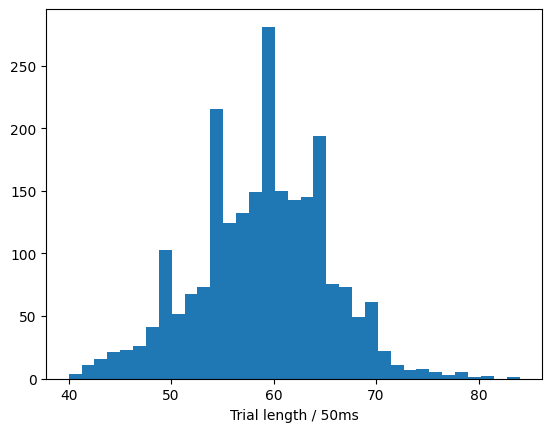

In [ ]:
trial_lengths = [(end - start) // 50 for start, end in zip(trial_starts, trial_ends)]
plt.hist(trial_lengths, bins=35)
plt.xlabel("Trial length / 50ms")
plt.show()

## Spikes

In [9]:
spikes_trials = []
for start, end in zip(trial_starts, trial_ends):
    spikes_trial = spikes[start:end]
    spikes_trial = spikes_trial[:len(spikes_trial) // 50 * 50]  # make trial length divisible by 50
    spikes_trial = spikes_trial.reshape(-1, 50, spikes_trial.shape[1]).sum(axis=1)  # binning
    spikes_trials.append(spikes_trial)

In [ ]:
max_hand_position = np.nanmax(
    np.abs(dataset.data["hand_pos"].to_numpy()), axis=0)
max_eye_position = np.nanmax(
    np.abs(dataset.data["eye_pos"].to_numpy()), axis=0)
max_cursor_position = np.nanmax(
    np.abs(dataset.data["cursor_pos"].to_numpy()), axis=0)
max_target_position = np.max([np.max(np.abs(dataset.trial_info["target_pos"][i]), axis=0)
                             for i in range(len(dataset.trial_info["target_pos"]))], axis=0)

normalization_factor = np.max(
    [max_hand_position, max_cursor_position, max_target_position], axis=0)

In [ ]:
max_hand_position, max_eye_position, max_cursor_position, max_target_position, normalization_factor

(array([152.00769889, 170.56719167]),
 array([357.5, 342.5]),
 array([152.9       , 138.41092347]),
 array([133,  86], dtype=int16),
 array([152.9       , 170.56719167]))

## Cursor Position

In [ ]:
cursor_position = dataset.data["cursor_pos"].to_numpy()
cursor_position.shape

(6952301, 2)

In [ ]:
cursor_position_trials = []
for start, end in zip(trial_starts, trial_ends):
    cursor_position_trial = cursor_position[start:end]
    cursor_position_trial = cursor_position_trial[:len(cursor_position_trial) // 50 * 50]  # make trial length divisible by 50
    cursor_position_trial = cursor_position_trial.reshape(-1, 50, cursor_position_trial.shape[1]).mean(axis=1) # binning
    cursor_position_trials.append(cursor_position_trial / normalization_factor)

## Hand Position

In [ ]:
hand_position = dataset.data["hand_pos"].to_numpy()
hand_position.shape

(6952301, 2)

In [ ]:
# cursor position and hand position is exactly the same, except that y-coordinate is shifted by 35
np.nanmean(hand_position - cursor_position, axis=0), np.nanstd(hand_position - cursor_position, axis=0)

(array([ 2.75267980e-02, -3.49829615e+01]), array([0.75989243, 0.71573682]))

In [ ]:
hand_position_trials = []
for start, end in zip(trial_starts, trial_ends):
    hand_position_trial = hand_position[start:end] + np.array([0, 34.98])
    hand_position_trial = hand_position_trial[:len(hand_position_trial) // 50 * 50]  # make trial length divisible by 50
    hand_position_trial = hand_position_trial.reshape(-1, 50, hand_position_trial.shape[1]).mean(axis=1)  # binning
    hand_position_trials.append(hand_position_trial / normalization_factor)

## Eye Position

In [8]:
eye_position = dataset.data["eye_pos"].to_numpy()
eye_position.shape

(6952301, 2)

In [18]:
eye_position_trials = []
for start, end in zip(trial_starts, trial_ends):
    eye_position_trial = eye_position[start:end]
    eye_position_trial = eye_position_trial[:len(eye_position_trial) // 50 * 50]  # make trial length divisible by 50
    eye_position_trial = eye_position_trial.reshape(-1, 50, eye_position_trial.shape[1]).mean(axis=1) # binning
    eye_position_trials.append(eye_position_trial / normalization_factor)

## Externals

### Go Cue

In [19]:
# conver timedelta to seconds
go_cue_time = dataset.trial_info["go_cue_time"].to_numpy()
# convert from nanoseconds to milliseconds
go_cue_time = go_cue_time / 1e6

go_cues = np.zeros(spikes.shape[0])
# go_cues should be 1 at each entry of go_cue_time
go_cues[go_cue_time.astype(int)] = 1
go_cue_trials = []

for start, end in zip(trial_starts, trial_ends):
    go_cue_trial = go_cues[start:end]
    assert np.sum(go_cue_trial) == 1
    go_cue_trial = go_cue_trial[:len(go_cue_trial) // 50 * 50]  # make trial length divisible by 50
    go_cue_trial = go_cue_trial.reshape(-1, 50).sum(axis=1)  # binning
    go_cue_trials.append(go_cue_trial)

### Target Cue

In [20]:
# conver timedelta to seconds
target_cue_time = dataset.trial_info["target_on_time"].to_numpy()
# convert from nanoseconds to milliseconds
target_cue_time = target_cue_time / 1e6

target_cues = np.zeros(spikes.shape[0])
# target_cues should be 1 at each entry of target_cue_time
target_cues[target_cue_time.astype(int)] = 1
target_cue_trials = []

for start, end in zip(trial_starts, trial_ends):
    target_cue_trial = target_cues[start:end]
    assert np.sum(target_cue_trial) == 1
    target_cue_trial = target_cue_trial[:len(target_cue_trial) // 50 * 50]  # make trial length divisible by 50
    target_cue_trial = target_cue_trial.reshape(-1, 50).sum(axis=1)  # binning
    target_cue_trials.append(target_cue_trial)

### Target Position

In [21]:
target_position_trials = []
for i, (start, end) in enumerate(zip(trial_starts, trial_ends)):
    active_target_position = dataset.trial_info["target_pos"][i][dataset.trial_info["active_target"][i]]
    target_position = np.zeros(((end - start)//50, 2))
    # target position is shown after the target cue
    target_position[(target_cue_trials[i] == 1).argmax():] = active_target_position / normalization_factor
    target_position_trials.append(target_position)

## Barriers

## Plot

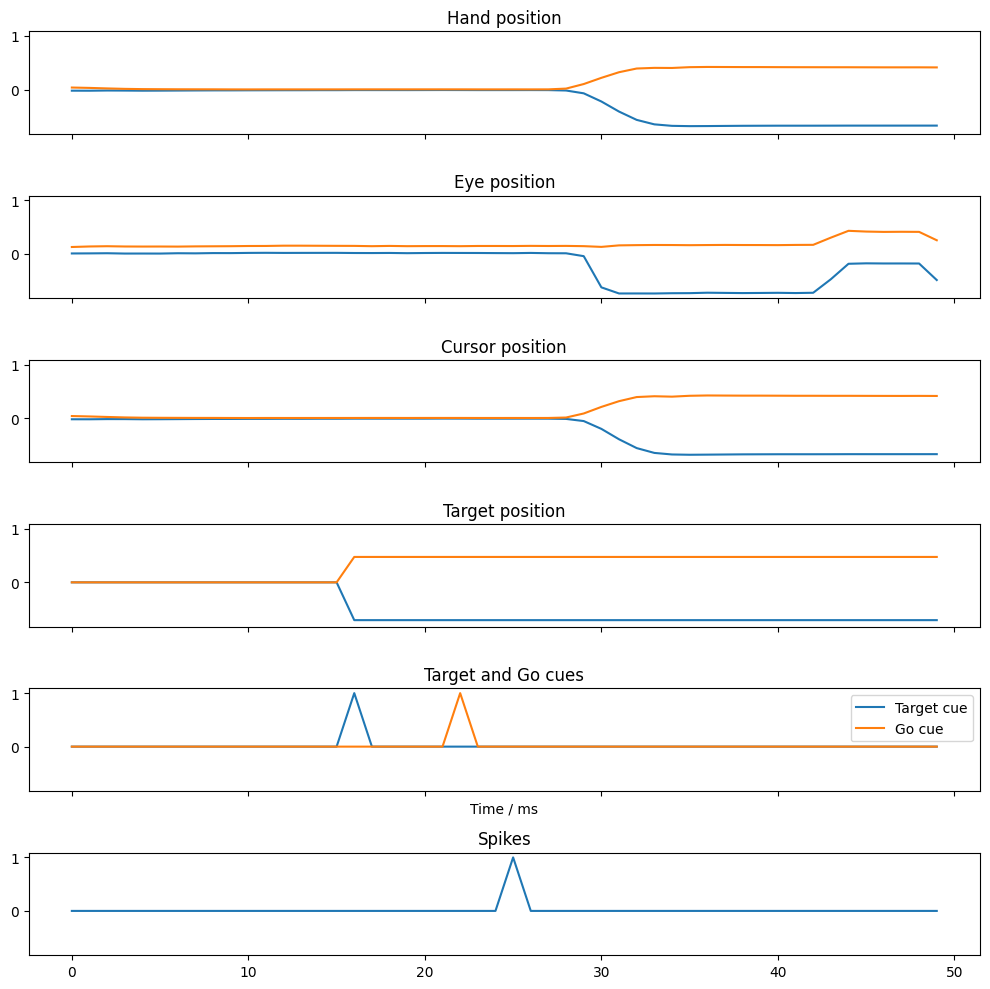

In [22]:
trial = 33
fig, axs = plt.subplots(6, 1, figsize=(10, 10), sharex=True, sharey=True)
axs[0].plot(hand_position_trials[trial])
axs[1].plot(eye_position_trials[trial])
axs[2].plot(cursor_position_trials[trial])
axs[3].plot(target_position_trials[trial])
axs[4].plot(target_cue_trials[trial])
axs[4].plot(go_cue_trials[trial])
axs[5].plot(spikes_trials[trial][:, 0])
axs[0].set_title("Hand position")
axs[1].set_title("Eye position")
axs[2].set_title("Cursor position")
axs[3].set_title("Target position")
axs[4].set_title("Target and Go cues")
axs[4].legend(["Target cue", "Go cue"])
axs[4].set_xlabel("Time / ms")
axs[5].set_title("Spikes")
plt.tight_layout()

## Saving

### saving 2 measurements

In [ ]:
# use only no-barrier trials
no_barrier_trials = dataset.trial_info["trial_version"].to_numpy() == 0

for k, measurement in enumerate(["/measurement1_no_barriers", "/measurement2_no_barriers"]):
    save_path = DATA_DIR + "/neuro_preprocessing/mc_maze_proprocessed" + measurement

    # observations
    spikes_trials_k = [spikes_trials[i] for i in range(
        len(spikes_trials)) if no_barrier_trials[i] and (i % 2 == k)]
    hand_position_trials_k = [hand_position_trials[i] for i in range(
        len(hand_position_trials)) if no_barrier_trials[i] and (i % 2 == k)]
    eye_position_trials_k = [eye_position_trials[i] for i in range(
        len(eye_position_trials)) if no_barrier_trials[i] and (i % 2 == k)]

    # externals
    target_position_trials_k = [target_position_trials[i] for i in range(
        len(target_position_trials)) if no_barrier_trials[i] and (i % 2 == k)]
    go_cue_trials_k = [go_cue_trials[i] for i in range(
        len(go_cue_trials)) if no_barrier_trials[i] and (i % 2 == k)]

    # assert same number of trials
    assert len(spikes_trials_k) == len(hand_position_trials_k) == len(
        eye_position_trials_k) == len(target_position_trials_k) == len(go_cue_trials_k)

    for i in range(len(spikes_trials_k)):
        # assert same trial length
        assert spikes_trials_k[i].shape[0] == hand_position_trials_k[i].shape[0] == eye_position_trials_k[
            i].shape[0] == target_position_trials_k[i].shape[0] == go_cue_trials_k[i].shape[0]
        # assert go cue is only 1 at one time point
        assert np.sum(go_cue_trials_k[i]) == 1
        # assert target position takes only 3 values
        assert np.unique(target_position_trials_k[i]).shape[0] == 3

    # save as pickled list
    with open(f"{save_path}/observations/1_spikes_trials.pkl", "wb") as f:
        pickle.dump(spikes_trials_k, f)
    with open(f"{save_path}/observations/2_hand_position_trials.pkl", "wb") as f:
        pickle.dump(hand_position_trials_k, f)
    with open(f"{save_path}/observations/3_eye_position_trials.pkl", "wb") as f:
        pickle.dump(eye_position_trials_k, f)
    with open(f"{save_path}/externals/target_position_trials.pkl", "wb") as f:
        pickle.dump(target_position_trials_k, f)
    with open(f"{save_path}/externals/go_cue_trials.pkl", "wb") as f:
        pickle.dump(go_cue_trials_k, f)